In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

In [8]:
df=pd.read_csv('ameshousing.csv')

In [9]:
print("Dataset loaded successfully")

print(df.head())

print("Shape:", df.shape)

print(df.info())

Dataset loaded successfully
   Order        PID  MS SubClass MS Zoning  Lot Frontage  Lot Area Street  \
0      1  526301100           20        RL         141.0     31770   Pave   
1      2  526350040           20        RH          80.0     11622   Pave   
2      3  526351010           20        RL          81.0     14267   Pave   
3      4  526353030           20        RL          93.0     11160   Pave   
4      5  527105010           60        RL          74.0     13830   Pave   

  Alley Lot Shape Land Contour Utilities Lot Config Land Slope Neighborhood  \
0   NaN       IR1          Lvl    AllPub     Corner        Gtl        NAmes   
1   NaN       Reg          Lvl    AllPub     Inside        Gtl        NAmes   
2   NaN       IR1          Lvl    AllPub     Corner        Gtl        NAmes   
3   NaN       Reg          Lvl    AllPub     Corner        Gtl        NAmes   
4   NaN       IR1          Lvl    AllPub     Inside        Gtl      Gilbert   

  Condition 1 Condition 2 Bldg Typ

In [10]:
print(df["SalePrice"].describe())

count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64


In [11]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(
    ascending=False
)

print(missing)

Pool QC           2917
Misc Feature      2824
Alley             2732
Fence             2358
Mas Vnr Type      1775
Fireplace Qu      1422
Lot Frontage       490
Garage Cond        159
Garage Qual        159
Garage Finish      159
Garage Yr Blt      159
Garage Type        157
Bsmt Exposure       83
BsmtFin Type 2      81
Bsmt Cond           80
Bsmt Qual           80
BsmtFin Type 1      80
Mas Vnr Area        23
Bsmt Half Bath       2
Bsmt Full Bath       2
BsmtFin SF 1         1
Garage Cars          1
Garage Area          1
Total Bsmt SF        1
Bsmt Unf SF          1
BsmtFin SF 2         1
Electrical           1
dtype: int64


In [12]:
print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates()

Duplicates: 0


In [13]:
df = df.dropna(subset=["SalePrice"])

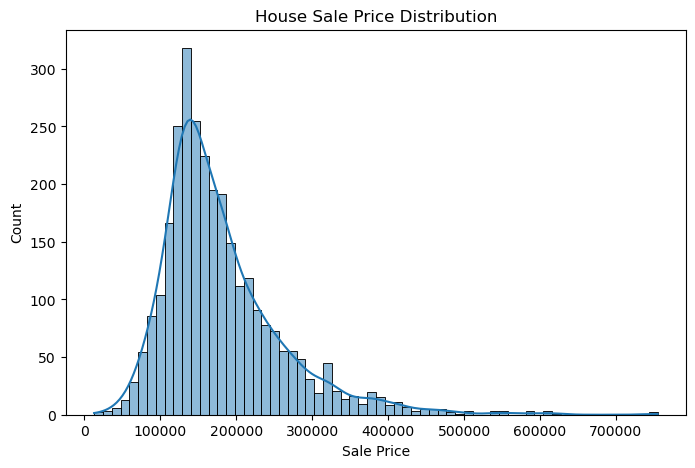

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(df["SalePrice"], kde=True)

plt.title("House Sale Price Distribution")
plt.xlabel("Sale Price")

plt.show()

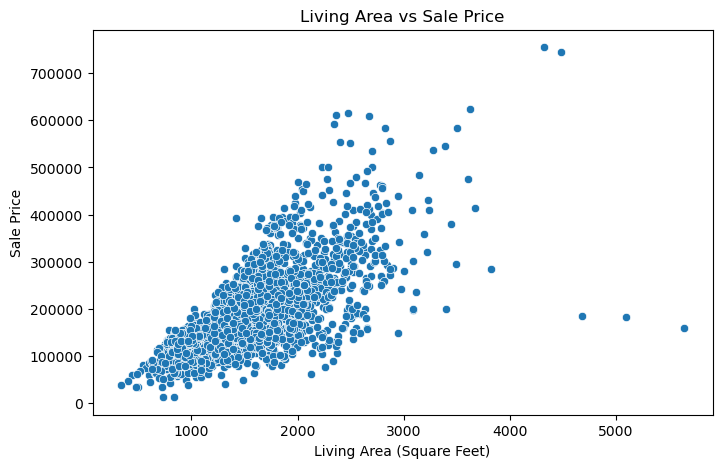

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Gr Liv Area",
    y="SalePrice"
)

plt.title("Living Area vs Sale Price")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("Sale Price")

plt.show()

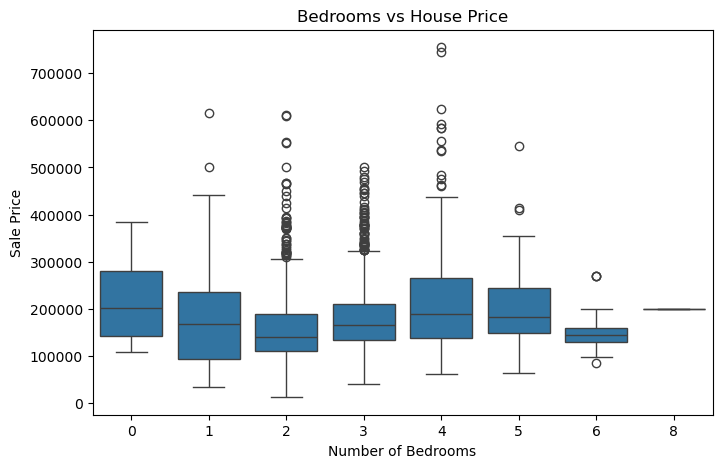

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Bedroom AbvGr",
    y="SalePrice"
)

plt.title("Bedrooms vs House Price")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Sale Price")

plt.show()

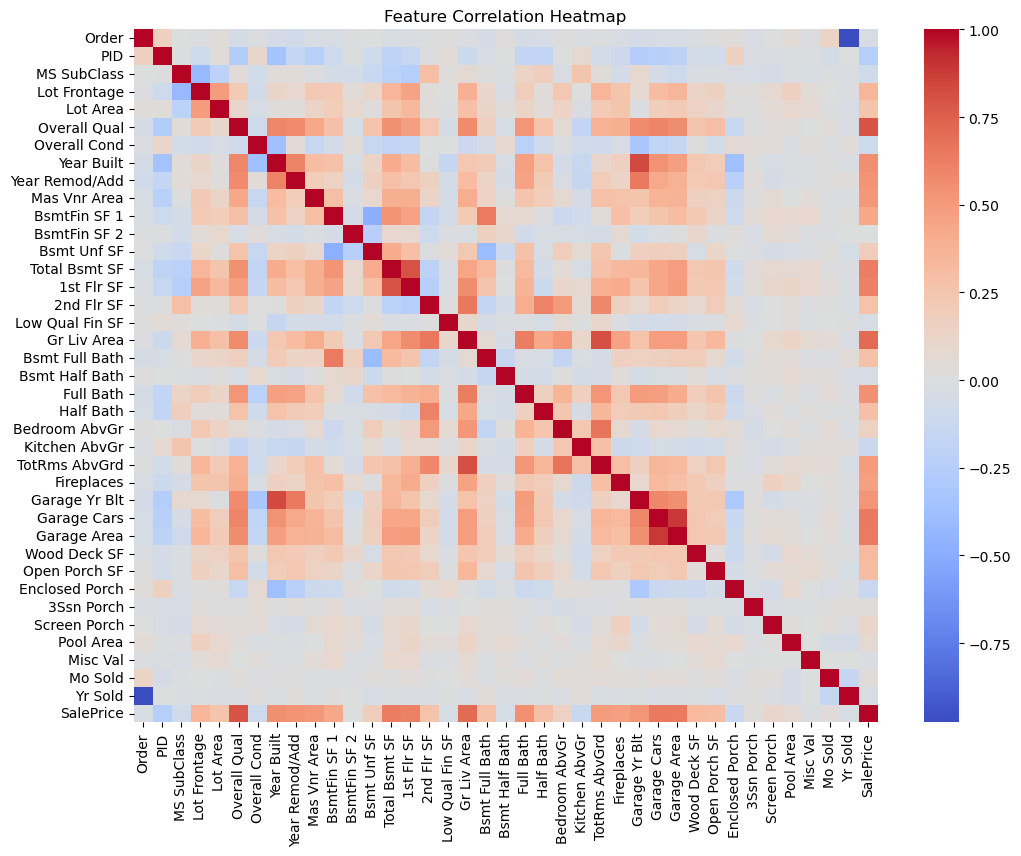

In [19]:
numeric_df = df.select_dtypes(
    include=["number"]
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    annot=False
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [20]:
# Remove identifier columns if present
drop_cols = ["SalePrice", "Id"]

X = df.drop(
    columns=[c for c in drop_cols if c in df.columns]
)

y = df["SalePrice"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (2930, 81)
Target: (2930,)


In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (2344, 81)
Testing: (586, 81)


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

In [23]:
from sklearn.linear_model import LinearRegression

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Order', 'PID',
                                                   'MS SubClass',
                                                   'Lot Frontage', 'Lot Area',
                                                   'Overall Qual',
                                                   'Overall Cond', 'Year Built',
                                                   'Year Remod/Add',
                                                   'Mas Vnr Area',
                                                   'BsmtFin SF 1',
                                                   'BsmtFin SF 2',
                                                   'Bsmt Unf SF',
                                                   'Total Bsmt SF',
                                                   '1st Flr SF', '2nd Flr SF',
                                                   'Low Qual Fin SF',
                                                   'G...
                                                   'Land Contour', 'Utilities',
                                                   'Lot Config', 'Land Slope',
                                                   'Neighborhood',
                                                   'Condition 1', 'Condition 2',
                                                   'Bldg Type', 'House Style',
                                                   'Roof Style', 'Roof Matl',
                                                   'Exterior 1st',
                                                   'Exterior 2nd',
                                                   'Mas Vnr Type', 'Exter Qual',
                                                   'Exter Cond', 'Foundation',
                                                   'Bsmt Qual', 'Bsmt Cond',
                                                   'Bsmt Exposure',
                                                   'BsmtFin Type 1',
                                                   'BsmtFin Type 2', 'Heating',
                                                   'Heating QC', 'Central Air',
                                                   'Electrical', ...])])),
                ('model', LinearRegression())])

In [24]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=20,
        min_samples_split=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Order', 'PID',
                                                   'MS SubClass',
                                                   'Lot Frontage', 'Lot Area',
                                                   'Overall Qual',
                                                   'Overall Cond', 'Year Built',
                                                   'Year Remod/Add',
                                                   'Mas Vnr Area',
                                                   'BsmtFin SF 1',
                                                   'BsmtFin SF 2',
                                                   'Bsmt Unf SF',
                                                   'Total Bsmt SF',
                                                   '1st Flr SF', '2nd Flr SF',
                                                   'Low Qual Fin SF',
                                                   'G...
                                                   'Condition 1', 'Condition 2',
                                                   'Bldg Type', 'House Style',
                                                   'Roof Style', 'Roof Matl',
                                                   'Exterior 1st',
                                                   'Exterior 2nd',
                                                   'Mas Vnr Type', 'Exter Qual',
                                                   'Exter Cond', 'Foundation',
                                                   'Bsmt Qual', 'Bsmt Cond',
                                                   'Bsmt Exposure',
                                                   'BsmtFin Type 1',
                                                   'BsmtFin Type 2', 'Heating',
                                                   'Heating QC', 'Central Air',
                                                   'Electrical', ...])])),
                ('model',
                 RandomForestRegressor(max_depth=20, n_estimators=300,
                                       n_jobs=-1, random_state=42))])

In [25]:
from xgboost import XGBRegressor

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=500,
        max_depth=4,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

ModuleNotFoundError: No module named 'xgboost'

In [26]:
%pip install xgboost scikit-learn

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 16.4 MB/s eta 0:00:03
    --------------------------------------- 0.8/48.9 MB 3.4 MB/s eta 0:00:15
    --------------------------------------- 1.0/48.9 MB 2.0 MB/s eta 0:00:24
   - -------------------------------------- 1.8/48.9 MB 2.6 MB/s eta 0:00:18
   -- ------------------------------------- 2.9/48.9 MB 3.2 MB/s eta 0:00:15
   -- ------------------------------------- 3.7/48.9 MB 3.3 MB/s eta 0:00:14
   --- ------------------------------------ 4.7/48.9 MB 3.5 MB/s eta 0:00:13
   ---- ----------------------------------- 5.5/48.9 MB 3.5 MB/s eta 0:00:13
   ----- ---------------------------------- 6.3/48.9 MB 3.5 MB/s eta 0:00:13
   ----- ---------------------------------- 6.8/48.9 MB 3.5 MB/s eta 0:00:13
   ------ --------------------------------- 7.9/48.9 MB 3.6 MB/s eta 0:00:12
   ------- -------------------------------- 8.7/48.9 MB 3.7 MB/s eta 0:00:12
   --

In [27]:
from xgboost import XGBRegressor

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=500,
        max_depth=4,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Order', 'PID',
                                                   'MS SubClass',
                                                   'Lot Frontage', 'Lot Area',
                                                   'Overall Qual',
                                                   'Overall Cond', 'Year Built',
                                                   'Year Remod/Add',
                                                   'Mas Vnr Area',
                                                   'BsmtFin SF 1',
                                                   'BsmtFin SF 2',
                                                   'Bsmt Unf SF',
                                                   'Total Bsmt SF',
                                                   '1st Flr SF', '2nd Flr SF',
                                                   'Low Qual Fin SF',
                                                   'G...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.03,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=4, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=500, n_jobs=-1,
                              num_parallel_tree=None, ...))])

In [28]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_squared_log_error
)

models = {
    "Linear Regression": linear_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    predictions = np.maximum(predictions, 0)

    mae = mean_absolute_error(
        y_test, predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(y_test, predictions)

    rmsle = np.sqrt(
        mean_squared_log_error(y_test, predictions)
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "RMSLE": rmsle
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values("RMSE"))

               Model           MAE          RMSE        R2     RMSLE
2            XGBoost  13867.182504  22538.552478  0.936641  0.106214
1      Random Forest  15835.936940  26842.335903  0.910133  0.123029
0  Linear Regression  29685.154171  45959.399310  0.736545  0.206622


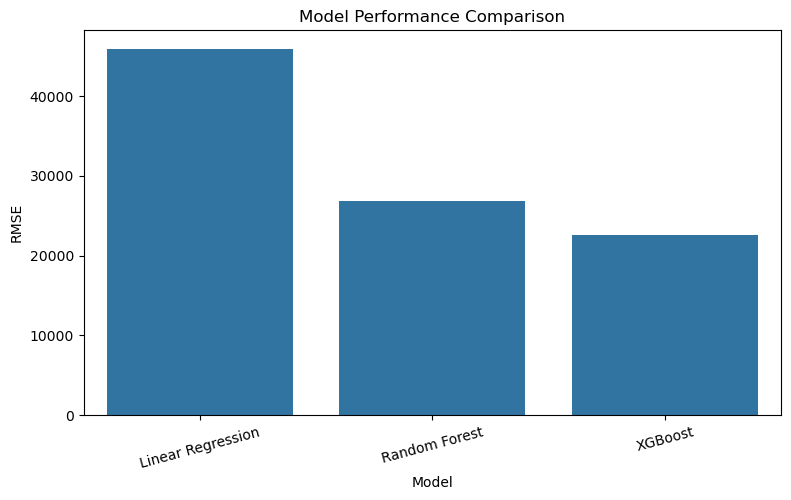

In [29]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("Model Performance Comparison")
plt.xticks(rotation=15)

plt.show()

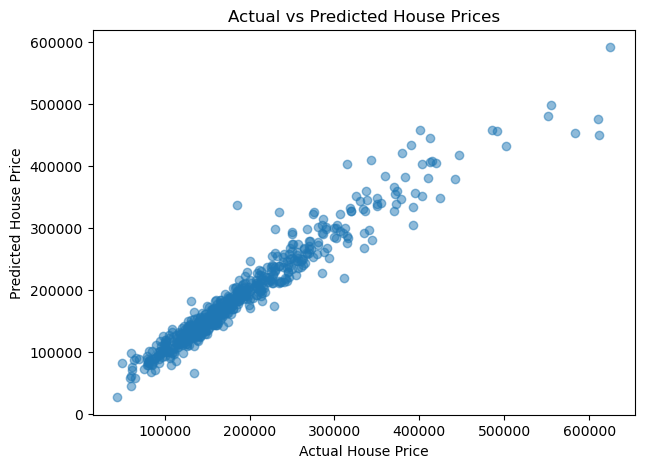

Best model: XGBoost


In [30]:
best_model_name = results_df.sort_values(
    "RMSE"
).iloc[0]["Model"]

best_model = models[best_model_name]

predictions = np.maximum(
    best_model.predict(X_test), 0
)

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    predictions,
    alpha=0.5
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")

plt.title("Actual vs Predicted House Prices")

plt.show()

print("Best model:", best_model_name)

In [31]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    best_model,
    "models/house_price_model.pkl"
)

joblib.dump(
    list(X.columns),
    "models/feature_columns.pkl"
)

# Save a typical input row for the dashboard
joblib.dump(
    X_train.iloc[0].to_dict(),
    "models/default_values.pkl"
)

print("Best model saved successfully!")

Best model saved successfully!
